In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
E = np.linspace(20, 100, 900)
m = 1
V0 = 1
h = 1
a = 1
k = np.sqrt(2*m*(E))/h
q = np.sqrt(2*m*(E - V0))/h
P = 1 - 1/(1+(k**2-q**2)**2/(4*k **2 *q ** 2)*(np.sin(2*q*a)**2))

In [3]:
P2 = (V0/(2*E))**2 * (np.sin(2*k*a))**2

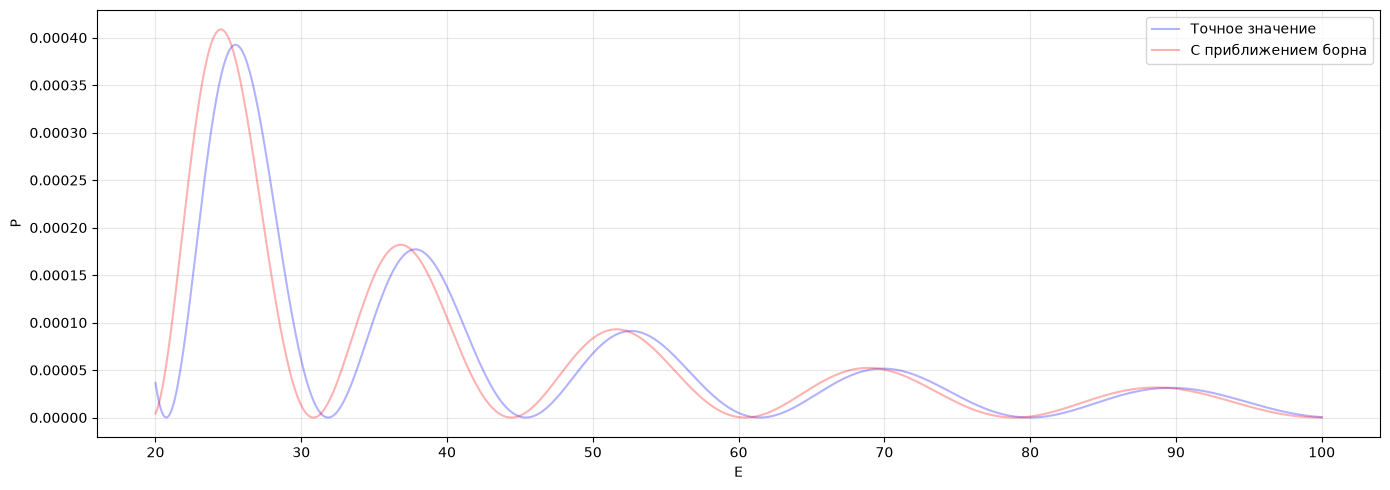

<Figure size 640x480 with 0 Axes>

In [4]:
E = np.linspace(20, 100, 900)
m = 1
V0 = 1
h = 1
a = 1
k = np.sqrt(2*m*(E))/h
q = np.sqrt(2*m*(E - V0))/h
P = 1 - 1/(1+(k**2-q**2)**2/(4*k **2 *q ** 2)*(np.sin(2*q*a)**2))

P2 = (V0/(2*E))**2 * (np.sin(2*k*a))**2

fix, ax = plt.subplots(figsize = (14,5))
ax.plot(E, P, color = 'blue',alpha = 0.3, label = 'Точное значение')
ax.set_xlabel('E')
ax.set_ylabel('P')
ax.plot(E, P2, color = 'red', alpha = 0.3, label = 'С приближением борна')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
plt.tight_layout()
plt.show()

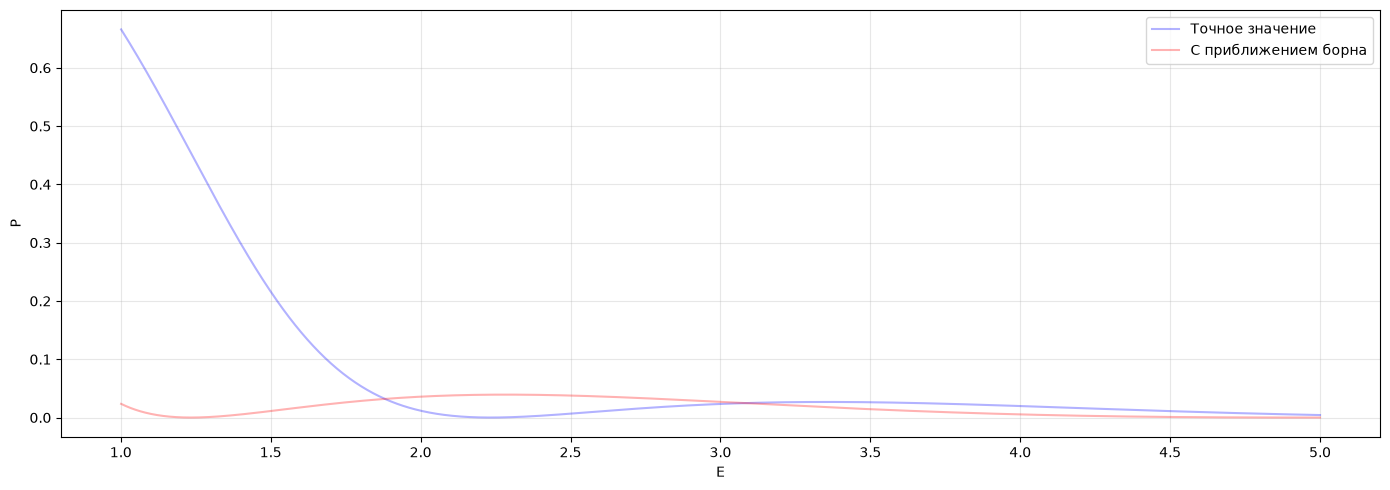

In [5]:
E = np.linspace(1.001,5, 1000)
m = 1
V0 = 1
h = 1
a = 1
k = np.sqrt(2*m*(E))/h
q = np.sqrt(2*m*(E - V0))/h
P = 1/(1+(k**2-q**2)**2/(4*k **2 *q ** 2)*(np.sin(2*q*a)**2))
P2 = (V0/(2*E))**2 * (np.sin(2*k*a))**2
T = 1 - P
fix, ax = plt.subplots(figsize = (14,5))
ax.plot(E, T, color = 'blue',alpha = 0.3, label = 'Точное значение')
ax.set_xlabel('E')
ax.set_ylabel('P')
ax.plot(E, P2, color = 'red', alpha = 0.3, label = 'С приближением борна')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

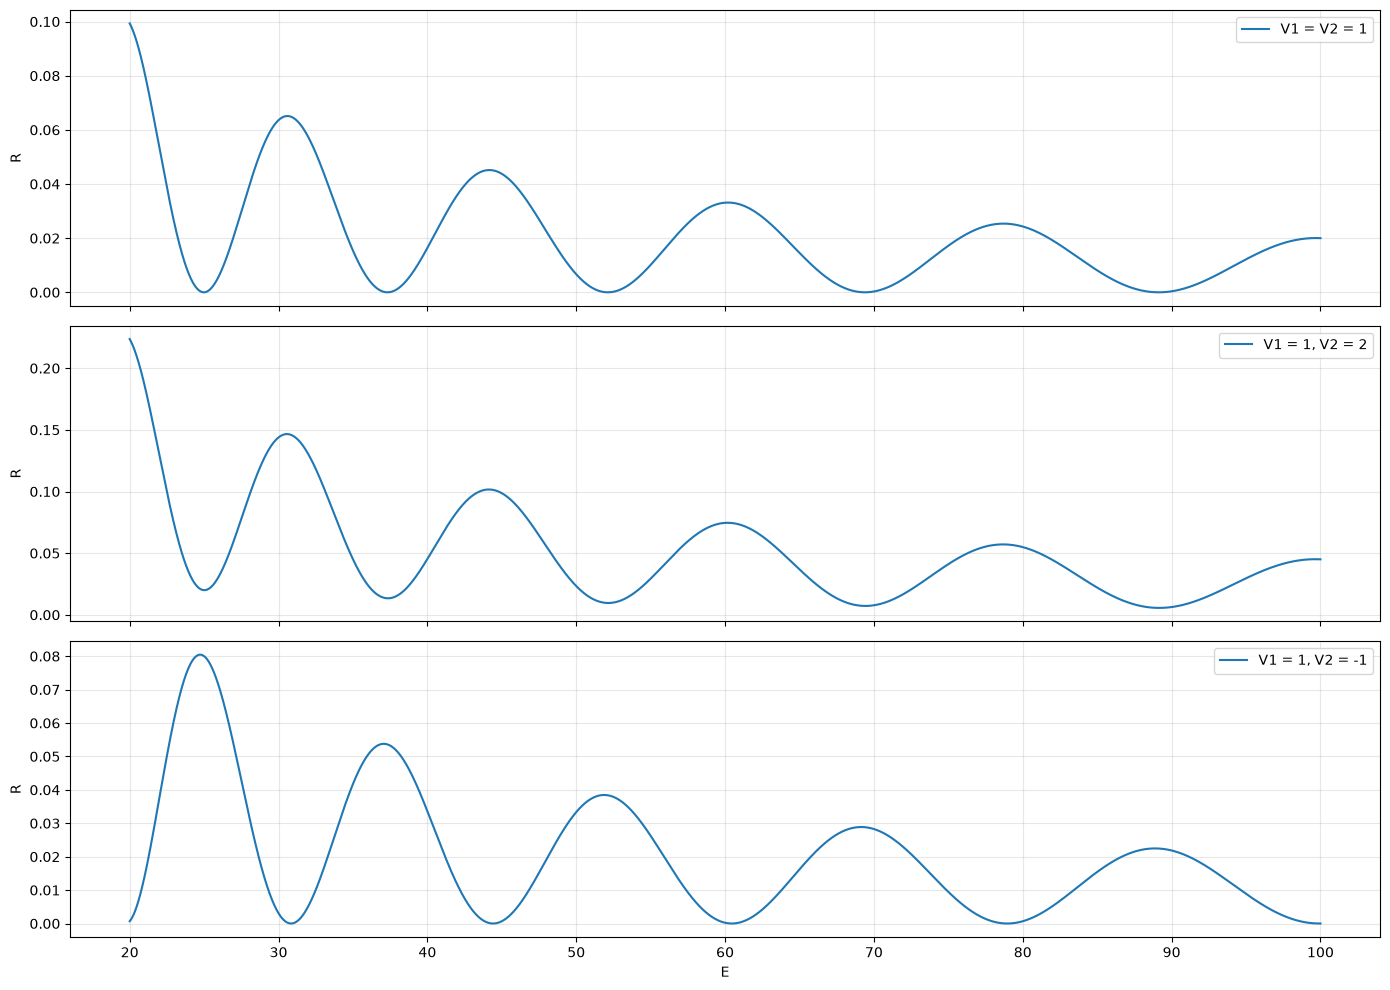

In [6]:
E = np.linspace(20, 100, 5000)

m = 1
hbar = 1
a = 1

k = np.sqrt(2 * m * E) / hbar

V1, V2 = 1, 1
R1 = m**2 / (hbar**4 * k**2) * (
    V1**2 + V2**2 + 2 * V1 * V2 * np.cos(4 * k * a)
)

V1, V2 = 1, 2
R2 = m**2 / (hbar**4 * k**2) * (
    V1**2 + V2**2 + 2 * V1 * V2 * np.cos(4 * k * a)
)

V1, V2 = 1, -1
R3 = m**2 / (hbar**4 * k**2) * (
    V1**2 + V2**2 + 2 * V1 * V2 * np.cos(4 * k * a)
)

fig, ax = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

ax[0].plot(E, R1, label='V1 = V2 = 1')
ax[1].plot(E, R2, label='V1 = 1, V2 = 2')
ax[2].plot(E, R3, label='V1 = 1, V2 = -1')

for axis in ax:
    axis.set_ylabel('R')
    axis.legend()
    axis.grid(alpha=0.3)

ax[2].set_xlabel('E')

plt.tight_layout()
plt.show()

### Проверка
Формула: $E=mc^2$

### Прохождение частицы через прямоугольный потенциальный барьер

Рассмотрим потенциал:

$$
V(x)=
\begin{cases}
V_0, & |x|<a,\\
0, & |x|>a.
\end{cases}
$$

Здесь $V_0>0$, а частица падает слева с энергией $E>V_0$.

Сравним точную вероятность прохождения с результатом первого приближения Борна.

### Точное решение

Сшивка волновой функции и её производной при $x=\pm a$ даёт:

$$
T_{\mathrm{exact}}=
\left[
1+\frac{V_0^2}{4E(E-V_0)}\sin^2(2qa)
\right]^{-1},
\qquad
q=\frac{\sqrt{2m(E-V_0)}}{\hbar}.
$$

### Свободная функция Грина

Определим свободную функцию Грина:

$$
\left[
-\frac{\hbar^2}{2m}\frac{d^2}{dx^2}-E-i\eta
\right]G_{0,\eta}(x,x')
=\delta(x-x'),
\qquad \eta>0.
$$

Решение, затухающее на обеих бесконечностях, имеет вид:

$$
G_{0,\eta}(x,x')
=\frac{im}{\hbar^2k_\eta}e^{ik_\eta|x-x'|},
$$

$$
k_\eta=\frac{\sqrt{2m(E+i\eta)}}{\hbar},
\qquad \operatorname{Im}k_\eta>0.
$$

Берём предел $\eta\to0^+$ и получаем уходящую функцию Грина:

$$
G_0(x,x')
=\frac{im}{\hbar^2k}e^{ik|x-x'|},
\qquad
k=\frac{\sqrt{2mE}}{\hbar}.
$$

### Первое приближение Борна

Перенесём потенциал в правую часть уравнения Шрёдингера:

$$
\left[
-\frac{\hbar^2}{2m}\frac{d^2}{dx^2}-E
\right]\psi(x)
=-V(x)\psi(x).
$$

Используя функцию Грина и добавляя падающую волну, получаем точное интегральное уравнение:

$$
\psi(x)=e^{ikx}
-\int_{-\infty}^{\infty}
G_0(x,x')V(x')\psi(x')\,dx'.
$$

Первое приближение Борна заключается в замене неизвестной функции под интегралом на падающую волну:

$$
\psi(x')\approx e^{ikx'}.
$$

Тогда:

$$
\psi_{\mathrm B}(x)=e^{ikx}
-\frac{im}{\hbar^2k}
\int_{-a}^{a}
e^{ik|x-x'|}V_0e^{ikx'}\,dx'.
$$

Слева от барьера, при $x<-a$, имеем $|x-x'|=x'-x$. Поэтому:

$$
\psi_{\mathrm B}(x)=e^{ikx}+r_{\mathrm B}e^{-ikx},
$$

где амплитуда отражения равна:

$$
r_{\mathrm B}
=-\frac{im}{\hbar^2k}
\int_{-a}^{a}V_0e^{2ikx'}\,dx'
=-\frac{imV_0}{\hbar^2k^2}\sin(2ka).
$$

Вероятность отражения:

$$
R_{\mathrm B}=|r_{\mathrm B}|^2
=\frac{V_0^2}{4E^2}\sin^2(2ka).
$$

По сохранению вероятности оцениваем прохождение:

$$
T_{\mathrm B}\approx1-R_{\mathrm B}
=1-\frac{V_0^2}{4E^2}\sin^2(2ka).
$$

Амплитуда отражения вычислена в первом порядке по потенциалу. Её квадрат даёт ведущую поправку второго порядка к вероятности прохождения.

### Безразмерные величины

Введём безразмерную энергию и параметр барьера:

$$
\varepsilon=\frac{E}{V_0}>1,
\qquad
\Lambda=\frac{2a\sqrt{2mV_0}}{\hbar}.
$$

Тогда:

$$
2ka=\Lambda\sqrt{\varepsilon},
\qquad
2qa=\Lambda\sqrt{\varepsilon-1}.
$$

Точное прохождение:

$$
T_{\mathrm{exact}}(\varepsilon)=
\left[
1+\frac{\sin^2(\Lambda\sqrt{\varepsilon-1})}
{4\varepsilon(\varepsilon-1)}
\right]^{-1}.
$$

Прохождение в приближении Борна:

$$
T_{\mathrm B}(\varepsilon)\approx
1-\frac{\sin^2(\Lambda\sqrt{\varepsilon})}{4\varepsilon^2}.
$$

При фиксированном $\Lambda$ и достаточно больших энергиях приближение Борна улучшается. Вблизи высоты барьера, $\varepsilon\approx1$, расхождение может быть существенным.

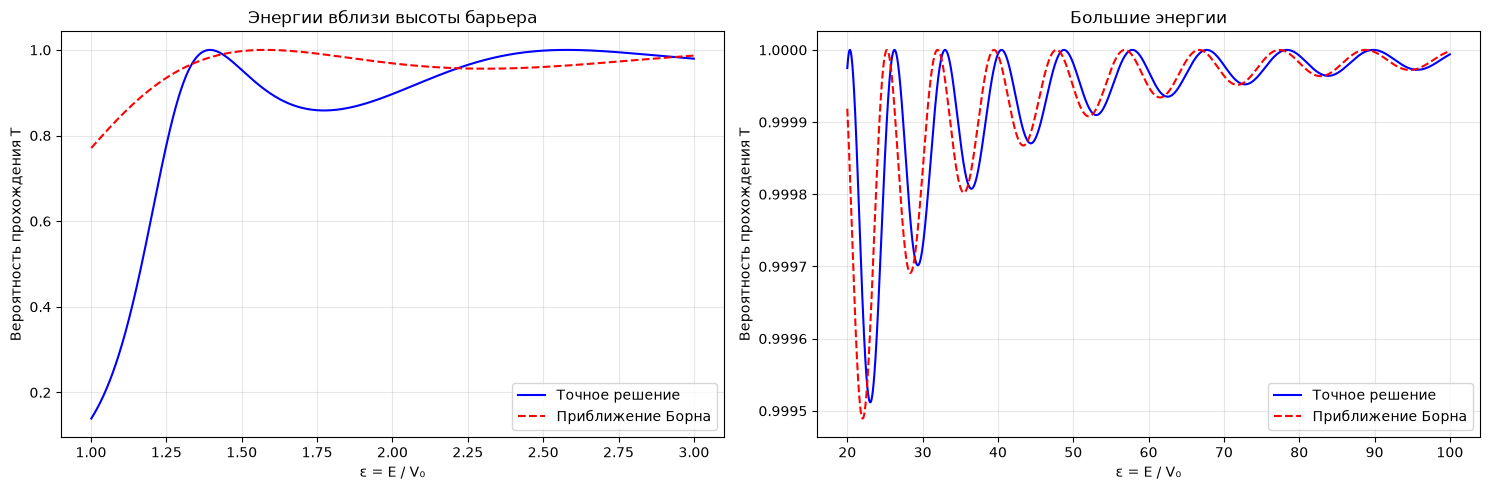

In [7]:
import numpy as np
import matplotlib.pyplot as plt

Lambda = 5.0

eps_low = np.linspace(1.001, 3, 5000)
eps_high = np.linspace(20, 100, 10000)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

for axis, eps, title in zip(
    ax,
    [eps_low, eps_high],
    ['Энергии вблизи высоты барьера', 'Большие энергии']
):
    T_exact = 1 / (
        1 + np.sin(Lambda * np.sqrt(eps - 1))**2
        / (4 * eps * (eps - 1))
    )

    R_born = np.sin(Lambda * np.sqrt(eps))**2 / (4 * eps**2)
    T_born = 1 - R_born

    axis.plot(eps, T_exact, label='Точное решение', color='blue')
    axis.plot(eps, T_born, '--', label='Приближение Борна', color='red')

    axis.set_xlabel('ε = E / V₀')
    axis.set_ylabel('Вероятность прохождения T')
    axis.set_title(title)
    axis.legend()
    axis.grid(alpha=0.3)
    axis.ticklabel_format(axis='y', style='plain', useOffset=False)

plt.tight_layout()
plt.show()

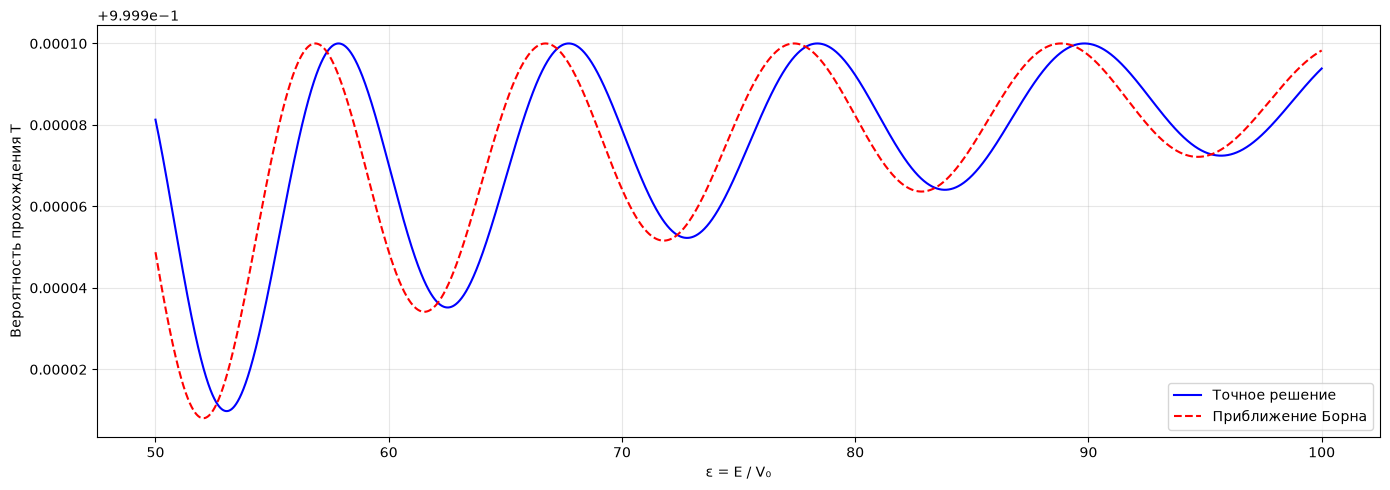

In [8]:
eps = np.linspace(50, 100, 10000)  # E / V0
Lambda = 5.0

T_exact = 1 / (
    1 + np.sin(Lambda * np.sqrt(eps - 1))**2
    / (4 * eps * (eps - 1))
)

R_born = np.sin(Lambda * np.sqrt(eps))**2 / (4 * eps**2)

T_born = 1 - R_born

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(eps, T_exact, label='Точное решение', color='blue')
ax.plot(eps, T_born, '--', label='Приближение Борна', color='red')

ax.set_xlabel('ε = E / V₀')
ax.set_ylabel('Вероятность прохождения T')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Рассеяние на прямоугольной потенциальной яме

Рассмотрим потенциал
$$
V(x)=
\begin{cases}
-V_0, & |x|<a,\\
0, & |x|>a,
\end{cases}
\qquad V_0>0.
$$
Частица падает слева с энергией $E>0$.
Внутри ямы её кинетическая энергия увеличивается:
$$
k=\frac{\sqrt{2mE}}{\hbar},
\qquad
q=\frac{\sqrt{2m(E+V_0)}}{\hbar}.
$$

Точная вероятность прохождения получается сшивкой
волновой функции и её производной на границах:
$$
T_{\mathrm{exact}}=
\left[
1+\frac{V_0^2}{4E(E+V_0)}\sin^2(2qa)
\right]^{-1}.
$$

В первом приближении Борна амплитуда отражения равна
$$
r_{\mathrm B}
=-\frac{im}{\hbar^2k}\int_{-a}^{a}(-V_0)e^{2ikx}\,dx
=\frac{imV_0}{\hbar^2k^2}\sin(2ka).
$$
Следовательно,
$$
R_{\mathrm B}=
\frac{V_0^2}{4E^2}\sin^2(2ka),
\qquad
T_{\mathrm B}\approx1-R_{\mathrm B}.
$$
В первом приближении Борна вероятность отражения одинакова
для прямоугольной ямы и барьера одинаковых ширины и модуля
потенциала. Точные вероятности при этом различаются.

Введём безразмерные величины
$$
\varepsilon=\frac{E}{V_0}>0,
\qquad
\Lambda=\frac{2a\sqrt{2mV_0}}{\hbar}.
$$
Тогда
$$
T_{\mathrm{exact}}=
\left[
1+\frac{\sin^2(\Lambda\sqrt{\varepsilon+1})}
{4\varepsilon(\varepsilon+1)}
\right]^{-1},
$$
$$
T_{\mathrm B}\approx
1-\frac{\sin^2(\Lambda\sqrt{\varepsilon})}{4\varepsilon^2}.
$$

На графиках сравниваются малые и большие энергии.
При малых энергиях приближение Борна может давать
нефизические значения $T_{\mathrm B}<0$ — это признак
неприменимости приближения. Эти значения не обрезаются.

Для прямоугольной ямы ведущая оценка ВКБ без отражения
даёт $T_{\mathrm{ВКБ}}=1$, однако на резких границах ямы
условия применимости ВКБ нарушаются.

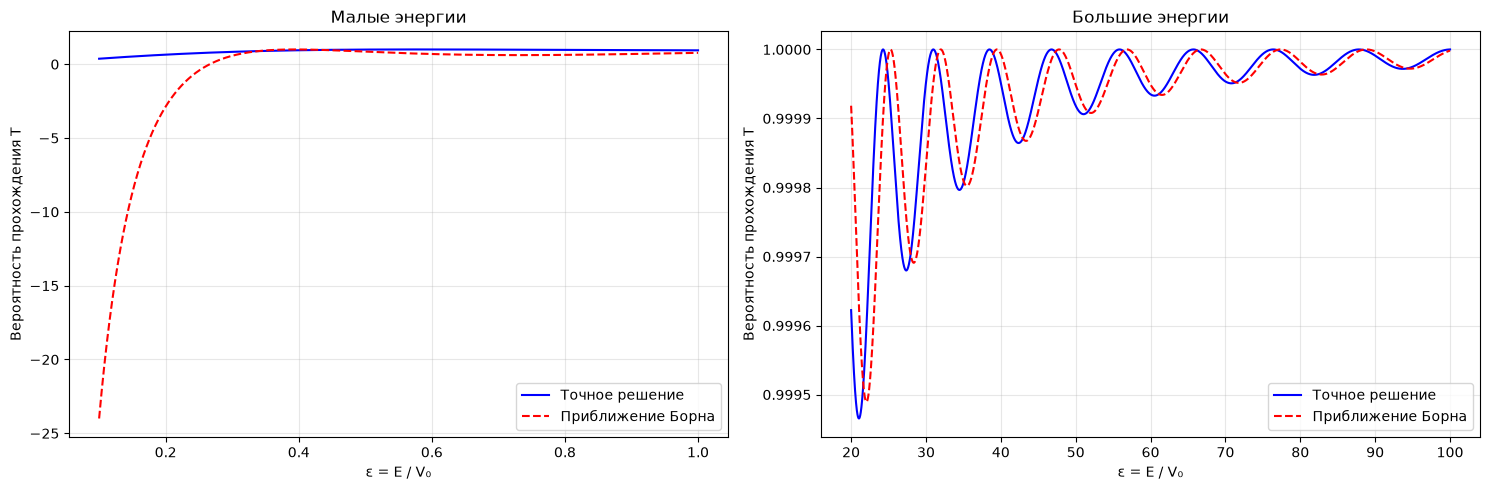

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Безразмерный параметр ширины и глубины ямы
Lambda = 5.0

eps_low = np.linspace(0.1, 1, 5000)
eps_high = np.linspace(20, 100, 10000)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

for axis, eps, title in zip(
    ax,
    [eps_low, eps_high],
    ['Малые энергии', 'Большие энергии']
):
    T_exact = 1 / (
        1 + np.sin(Lambda * np.sqrt(eps + 1))**2
        / (4 * eps * (eps + 1))
    )
    R_born = np.sin(Lambda * np.sqrt(eps))**2 / (4 * eps**2)
    T_born = 1 - R_born

    axis.plot(eps, T_exact, color='blue', label='Точное решение')
    axis.plot(eps, T_born, '--', color='red',
              label='Приближение Борна')

    axis.set_xlabel('ε = E / V₀')
    axis.set_ylabel('Вероятность прохождения T')
    axis.set_title(title)
    axis.legend()
    axis.grid(alpha=0.3)
    axis.ticklabel_format(axis='y', style='plain', useOffset=False)

plt.tight_layout()
plt.show()

### Точное прохождение через два дельта-потенциала

Рассмотрим одномерный потенциал
$$
U(x)=g_1\delta(x)+g_2\delta(x-L), \qquad L>0.
$$

Коэффициенты $g_1,g_2$ имеют размерность «энергия × длина».
При $g_i>0$ соответствующий потенциал является барьером,
при $g_i<0$ — ямой.

Частица падает слева с энергией $E>0$. Введём
$$
k=\frac{\sqrt{2mE}}{\hbar},
\qquad
\beta_1=\frac{mg_1}{\hbar^2k},
\qquad
\beta_2=\frac{mg_2}{\hbar^2k}.
$$

Вне точек $x=0$ и $x=L$ потенциал равен нулю, поэтому
волновая функция имеет вид
$$
\psi(x)=
\begin{cases}
e^{ikx}+r e^{-ikx}, & x<0,\\
A e^{ikx}+B e^{-ikx}, & 0<x<L,\\
t e^{ikx}, & x>L.
\end{cases}
$$

Здесь $r$ и $t$ — амплитуды отражения и прохождения.

### Граничные условия

В точке расположения дельта-потенциала волновая функция
непрерывна, а её производная испытывает скачок:
$$
\psi(x_i+0)=\psi(x_i-0),
$$
$$
\psi'(x_i+0)-\psi'(x_i-0)
=\frac{2mg_i}{\hbar^2}\psi(x_i).
$$

Условие на скачок получается интегрированием уравнения Шрёдингера
по бесконечно малому интервалу около $x_i$.

В точке $x=0$:
$$
1+r=A+B,
$$
$$
ik(A-B-1+r)=\frac{2mg_1}{\hbar^2}(1+r).
$$

В точке $x=L$:
$$
A e^{ikL}+B e^{-ikL}=t e^{ikL},
$$
$$
ik\left(t e^{ikL}-A e^{ikL}+B e^{-ikL}\right)
=\frac{2mg_2}{\hbar^2}t e^{ikL}.
$$

Из условий в точке $x=L$:
$$
B=-i\beta_2 t e^{2ikL},
\qquad
A=(1+i\beta_2)t.
$$

Из условий в точке $x=0$, исключая $r$, получаем:
$$
1=(1+i\beta_1)A+i\beta_1B.
$$

Подставляя найденные $A$ и $B$, находим:
$$
t(E)=
\frac{1}{
(1+i\beta_1)(1+i\beta_2)
+\beta_1\beta_2 e^{2ikL}
}.
$$

### Вероятность прохождения

Вероятность прохождения определяется отношением потоков:
$$
T=\frac{j_{\mathrm{trans}}}{j_{\mathrm{inc}}}.
$$

Слева и справа волновое число одинаково, поэтому
$$
T(E)=|t(E)|^2.
$$

Следовательно,
$$
T(E)=
\frac{1}{
\left|
(1+i\beta_1)(1+i\beta_2)
+\beta_1\beta_2e^{2ikL}
\right|^2
}.
$$

Эквивалентная вещественная формула:
$$
\boxed{
T(E)=
\frac{1}{
1+(\beta_1-\beta_2)^2\sin^2(kL)
+\left[
(\beta_1+\beta_2)\cos(kL)
+2\beta_1\beta_2\sin(kL)
\right]^2
}
}.
$$

Для вещественного потенциала выполняется
$$
R(E)+T(E)=1.
$$

### Симметричный случай и полное прохождение

При $g_1=g_2=g$ потенциал симметричен относительно $x=L/2$.
В этом случае $\beta_1=\beta_2=\beta$, поэтому
$$
T(E)=
\frac{1}{
1+4\beta^2\left[\cos(kL)+\beta\sin(kL)\right]^2
}.
$$

Полное прохождение $T=1$ достигается при
$$
\cos(kL)+\beta\sin(kL)=0.
$$

Для $g\ne 0$ это условие можно записать как
$$
\tan(kL)=-\frac{1}{\beta}
=-\frac{\hbar^2k}{mg}.
$$

Таким образом, при определённых дискретных энергиях
отражение полностью исчезает. Это результат интерференции
многократно отражённых между барьерами волн.

Для двух положительных барьеров разной силы
$g_1\ne g_2$ полное прохождение при конечной энергии невозможно:
два дополнительных квадрата в знаменателе не могут
одновременно обратиться в ноль.

При этом для любых фиксированных $g_1,g_2$:
$$
T(E)\longrightarrow 1 \qquad \text{при }E\longrightarrow\infty.
$$

### Безразмерные переменные для графика

Выберем масштаб энергии
$$
E_0=\frac{\hbar^2}{2mL^2}.
$$

Введём
$$
\varepsilon=\frac{E}{E_0},
\qquad
\lambda_i=\frac{mg_iL}{\hbar^2}.
$$

Тогда
$$
kL=\sqrt{\varepsilon},
\qquad
\beta_i=\frac{\lambda_i}{\sqrt{\varepsilon}}.
$$

У дельта-потенциала можно определить характерный масштаб энергии
$$
E_i^*=\frac{mg_i^2}{2\hbar^2}
=E_0\lambda_i^2.
$$

Он не является высотой барьера. Для отдельной дельта-ямы
это модуль энергии её связанного состояния.

Если требуется рассмотреть энергии выше обоих этих масштабов,
нужно выбрать
$$
\varepsilon>\max(\lambda_1^2,\lambda_2^2).
$$

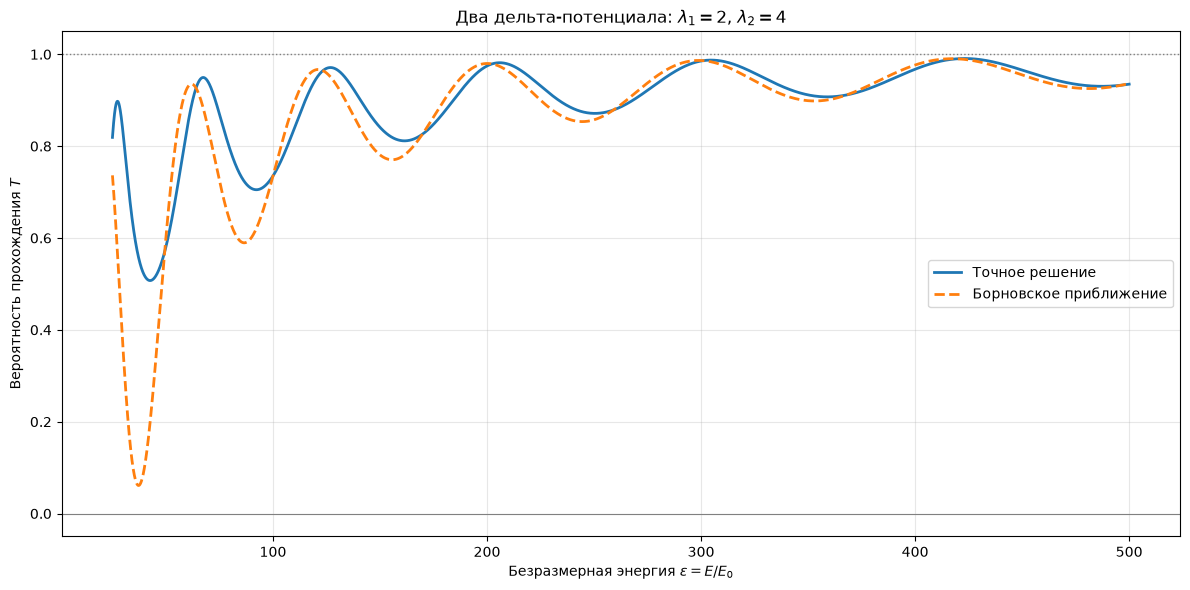

In [10]:
import numpy as np
import matplotlib.pyplot as plt

lambda_1 = 2
lambda_2 = 4


epsilon = np.linspace(25.01, 500, 30000)

q = np.sqrt(epsilon)


beta_1 = lambda_1 / q
beta_2 = lambda_2 / q



term_1 = (beta_1 - beta_2) * np.sin(q)

term_2 = (
    (beta_1 + beta_2) * np.cos(q)
    + 2 * beta_1 * beta_2 * np.sin(q)
)

T_exact = 1 / (1 + term_1**2 + term_2**2)

R_born = (
    beta_1**2
    + beta_2**2
    + 2 * beta_1 * beta_2 * np.cos(2 * q)
)

T_born = 1 - R_born


plt.figure(figsize=(12, 6))

plt.plot(
    epsilon,
    T_exact,
    label="Точное решение",
    linewidth=2,
)

plt.plot(
    epsilon,
    T_born,
    label="Борновское приближение",
    linestyle="--",
    linewidth=2,
)

plt.axhline(1, color="gray", linestyle=":", linewidth=1)
plt.axhline(0, color="gray", linewidth=0.8)

plt.xlabel(r"Безразмерная энергия $\varepsilon = E/E_0$")
plt.ylabel(r"Вероятность прохождения $T$")
plt.title(
    rf"Два дельта-потенциала: "
    rf"$\lambda_1={lambda_1:g}$, $\lambda_2={lambda_2:g}$"
)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

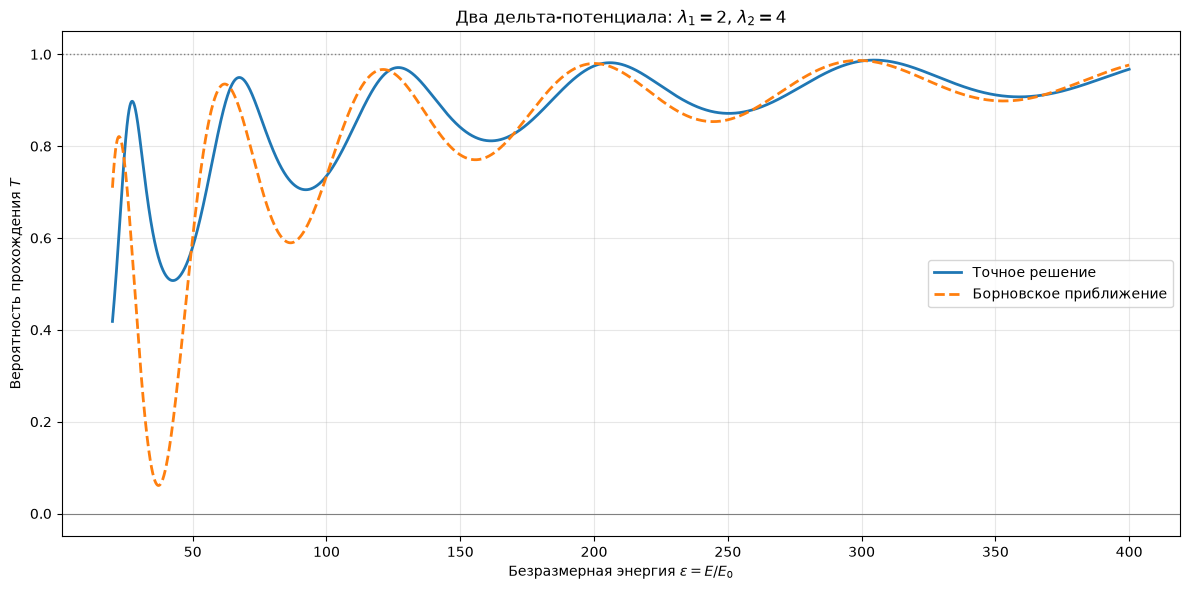

In [11]:
import numpy as np
import matplotlib.pyplot as plt

lambda_1 = 2
lambda_2 = 4


epsilon = np.linspace(20, 400, 30000)

q = np.sqrt(epsilon)


beta_1 = lambda_1 / q
beta_2 = lambda_2 / q



term_1 = (beta_1 - beta_2) * np.sin(q)

term_2 = (
    (beta_1 + beta_2) * np.cos(q)
    + 2 * beta_1 * beta_2 * np.sin(q)
)

T_exact = 1 / (1 + term_1**2 + term_2**2)

R_born = (
    beta_1**2
    + beta_2**2
    + 2 * beta_1 * beta_2 * np.cos(2 * q)
)

T_born = 1 - R_born


plt.figure(figsize=(12, 6))

plt.plot(
    epsilon,
    T_exact,
    label="Точное решение",
    linewidth=2,
)

plt.plot(
    epsilon,
    T_born,
    label="Борновское приближение",
    linestyle="--",
    linewidth=2,
)

plt.axhline(1, color="gray", linestyle=":", linewidth=1)
plt.axhline(0, color="gray", linewidth=0.8)

plt.xlabel(r"Безразмерная энергия $\varepsilon = E/E_0$")
plt.ylabel(r"Вероятность прохождения $T$")
plt.title(
    rf"Два дельта-потенциала: "
    rf"$\lambda_1={lambda_1:g}$, $\lambda_2={lambda_2:g}$"
)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

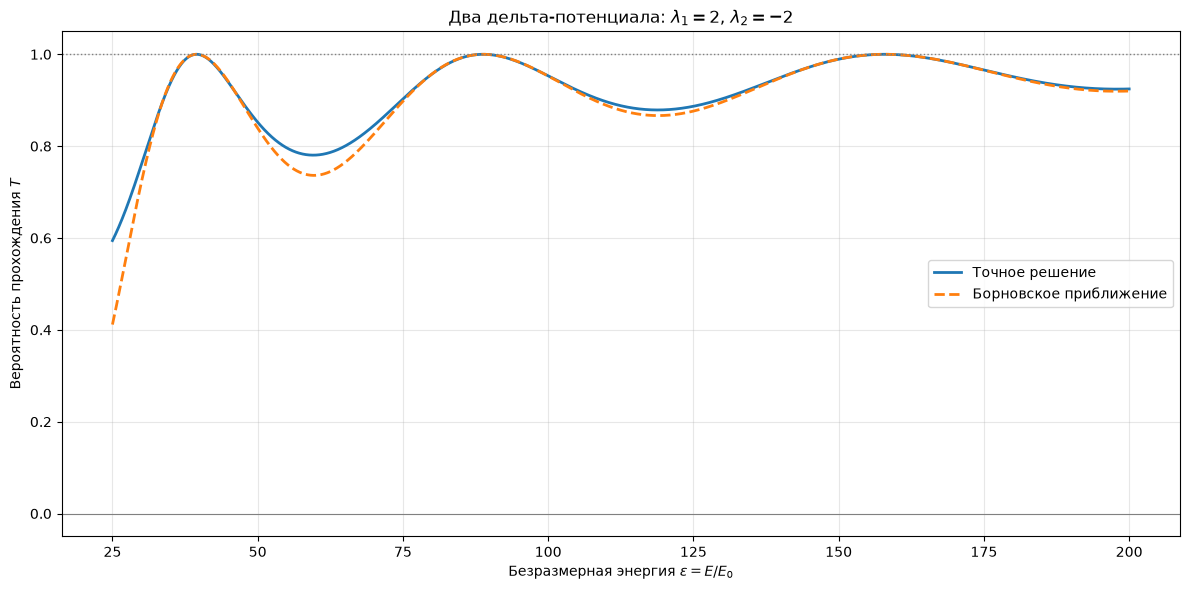

In [12]:
import numpy as np
import matplotlib.pyplot as plt

lambda_1 = 2
lambda_2 = -2


epsilon = np.linspace(25, 200, 30000)

q = np.sqrt(epsilon)


beta_1 = lambda_1 / q
beta_2 = lambda_2 / q



term_1 = (beta_1 - beta_2) * np.sin(q)

term_2 = (
    (beta_1 + beta_2) * np.cos(q)
    + 2 * beta_1 * beta_2 * np.sin(q)
)

T_exact = 1 / (1 + term_1**2 + term_2**2)

R_born = (
    beta_1**2
    + beta_2**2
    + 2 * beta_1 * beta_2 * np.cos(2 * q)
)

T_born = 1 - R_born


plt.figure(figsize=(12, 6))

plt.plot(
    epsilon,
    T_exact,
    label="Точное решение",
    linewidth=2,
)

plt.plot(
    epsilon,
    T_born,
    label="Борновское приближение",
    linestyle="--",
    linewidth=2,
)

plt.axhline(1, color="gray", linestyle=":", linewidth=1)
plt.axhline(0, color="gray", linewidth=0.8)

plt.xlabel(r"Безразмерная энергия $\varepsilon = E/E_0$")
plt.ylabel(r"Вероятность прохождения $T$")
plt.title(
    rf"Два дельта-потенциала: "
    rf"$\lambda_1={lambda_1:g}$, $\lambda_2={lambda_2:g}$"
)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Прохождение через треугольный потенциальный барьер

Рассмотрим частицу массы $m$ с энергией $E>0$, падающую слева на потенциал

$$
U(x)=
\begin{cases}
0, & |x|\ge a,\\
U_0(1+x/a), & -a<x<0,\\
U_0(1-x/a), & 0<x<a.
\end{cases}
$$

Нужно найти вероятность прохождения $T$ точно и в приближении ВКБ.

Введём безразмерные величины

$$
z=\frac{x}{a},\qquad
\varepsilon=\frac{E}{U_0},\qquad
\lambda=\frac{a\sqrt{2mU_0}}{\hbar},\qquad
q=ka=\lambda\sqrt{\varepsilon},
$$

где $k=\sqrt{2mE}/\hbar$ — волновое число вне барьера. Уравнение Шрёдингера принимает вид

$$
\frac{d^2\psi}{dz^2}
=\lambda^2\bigl(v(z)-\varepsilon\bigr)\psi,
\qquad
v(z)=\frac{U(az)}{U_0}.
$$

При $0<E<U_0$ внутри барьера есть классически запрещённая область. При $E\ge U_0$ её нет, но отражение всё ещё возможно.

## Точное решение через функции Эйри

Обозначим $\alpha=\lambda^{2/3}$. На левой и правой половинах барьера введём

$$
s_L(z)=\alpha(1+z-\varepsilon),\quad -1<z<0,
\qquad
s_R(z)=\alpha(1-z-\varepsilon),\quad 0<z<1.
$$

Например, слева $d^2\psi/dz^2=\alpha^2d^2\psi/ds_L^2$. С учётом $\alpha^3=\lambda^2$ уравнение Шрёдингера превращается в уравнение Эйри:

$$
\frac{d^2\psi}{ds^2}=s\psi.
$$

Следовательно, на каждой половине **точное** решение имеет вид

$$
\psi_L=A\operatorname{Ai}(s_L)+B\operatorname{Bi}(s_L),
\qquad
\psi_R=C\operatorname{Ai}(s_R)+D\operatorname{Bi}(s_R).
$$

Для сшивки удобно использовать вектор $Y=(\psi,d\psi/dz)^{\mathsf T}$. Тогда $Y=F_L(A,B)^{\mathsf T}$ слева и $Y=F_R(C,D)^{\mathsf T}$ справа, где

$$
F_L(z)=
\begin{pmatrix}
\operatorname{Ai}(s_L)&\operatorname{Bi}(s_L)\\
\alpha\operatorname{Ai}'(s_L)&\alpha\operatorname{Bi}'(s_L)
\end{pmatrix},
\qquad
F_R(z)=
\begin{pmatrix}
\operatorname{Ai}(s_R)&\operatorname{Bi}(s_R)\\
-\alpha\operatorname{Ai}'(s_R)&-\alpha\operatorname{Bi}'(s_R)
\end{pmatrix}.
$$

**Минус во второй строке $F_R$** возникает потому, что $ds_R/dz=-\alpha$.

Потенциал конечен, поэтому $\psi$ и $d\psi/dz$ непрерывны в точках $z=-1,0,1$. Передадим вектор $Y$ от левой границы к правой:

$$
Y(1)=P Y(-1),\qquad
P=F_R(1)F_R(0)^{-1}F_L(0)F_L(-1)^{-1}.
$$

Вне барьера запишем падающую, отражённую и прошедшую волны:

$$
\psi(z)=e^{iq(z+1)}+r e^{-iq(z+1)},\quad z\le-1;
\qquad
\psi(z)=t e^{iq(z-1)},\quad z\ge1.
$$

Пусть

$$
B_0=\begin{pmatrix}1&1\\iq&-iq\end{pmatrix},
\qquad M=B_0^{-1}PB_0.
$$

Тогда условие отсутствия волны, падающей справа, записывается как

$$
\begin{pmatrix}t\\0\end{pmatrix}
=M\begin{pmatrix}1\\r\end{pmatrix}.
$$

Отсюда, учитывая $\det P=\det M=1$,

$$
r=-\frac{M_{21}}{M_{22}},\qquad
t=\frac{1}{M_{22}}.
$$

Слева и справа волновое число одинаковое, поэтому отношение прошедшего и падающего потоков равно

$$
\boxed{T_{\mathrm{exact}}=|t|^2=\frac{1}{|M_{22}|^2}},
\qquad
R=|r|^2,\qquad R+T=1.
$$

Эта формула работает при любом $E>0$. Она включает и случай $E\ge U_0$.

## Приближение ВКБ

Пусть $0<E<U_0$, то есть $0<\varepsilon<1$. Точки поворота определяются условием $U(x)=E$:

$$
x_-=a(\varepsilon-1),
\qquad
x_+=a(1-\varepsilon).
$$

Подбарьерное действие

$$
S(E)=\frac{1}{\hbar}\int_{x_-}^{x_+}
\sqrt{2m\,[U(x)-E]}\,dx.
$$

Потенциал симметричен, поэтому достаточно вычислить интеграл на правой половине и удвоить:

$$
\begin{aligned}
S(E)
&=2\lambda\int_0^{1-\varepsilon}
\sqrt{1-\varepsilon-z}\,dz\\
&=2\lambda\left[
-\frac{2}{3}(1-\varepsilon-z)^{3/2}
\right]_0^{1-\varepsilon}\\
&=\frac{4\lambda}{3}(1-\varepsilon)^{3/2}.
\end{aligned}
$$

Ведущая экспоненциальная оценка ВКБ:

$$
\boxed{
T_{\mathrm{WKB}}\simeq e^{-2S}
=\exp\left[-\frac{8\lambda}{3}(1-\varepsilon)^{3/2}\right]
},\qquad 0<\varepsilon<1.
$$

Знак $\simeq$ существенен: здесь не вычислен множитель перед экспонентой. При $S\gg1$ оценка хорошо описывает основной порядок малой вероятности прохождения. Вблизи $E=U_0$ точки поворота сходятся у вершины и эта простая формула становится неточной. При $E\ge U_0$ запрещённой области нет, поэтому приведённую формулу для туннелирования не применяем.

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import airy


lam = 8.0
alpha = lam ** (2 / 3)

eps_grid = np.linspace(0.02, 2.0, 450)  # eps = E/U0
T_exact = []
R_exact = []
T_wkb = []

for eps in eps_grid:
    q = lam * np.sqrt(eps)

    s_edge = -alpha * eps        
    s_top = alpha * (1 - eps)    

    ai_e, aip_e, bi_e, bip_e = airy(s_edge)
    ai_0, aip_0, bi_0, bip_0 = airy(s_top)

    
    FL_minus = np.array([
        [ai_e, bi_e],
        [alpha * aip_e, alpha * bip_e],
    ])
    FL_zero = np.array([
        [ai_0, bi_0],
        [alpha * aip_0, alpha * bip_0],
    ])
    FR_zero = np.array([
        [ai_0, bi_0],
        [-alpha * aip_0, -alpha * bip_0],
    ])
    FR_plus = np.array([
        [ai_e, bi_e],
        [-alpha * aip_e, -alpha * bip_e],
    ])

    # P = FR(1) @ FR(0)^(-1) @ FL(0) @ FL(-1)^(-1).
    # solve(A, I) вычисляет A^(-1).
    P_left = FL_zero @ np.linalg.solve(FL_minus, np.eye(2))
    P_right = FR_plus @ np.linalg.solve(FR_zero, np.eye(2))
    P = P_right @ P_left

    B0 = np.array([
        [1, 1],
        [1j * q, -1j * q],
    ])
    M = np.linalg.solve(B0, P @ B0)

    t = 1 / M[1, 1]
    r = -M[1, 0] / M[1, 1]

    T_exact.append(abs(t) ** 2)
    R_exact.append(abs(r) ** 2)

    if eps < 1:
        S = 4 * lam * (1 - eps) ** 1.5 / 3
        T_wkb.append(np.exp(-2 * S))
    else:
        T_wkb.append(np.nan)  # Эта туннельная формула выше барьера неприменима.

T_exact = np.array(T_exact)
R_exact = np.array(R_exact)
T_wkb = np.array(T_wkb)

print("Максимальное отклонение R + T от 1:",
      np.max(np.abs(R_exact + T_exact - 1)))

for eps_requested in [0.2, 0.5, 0.8, 1.0, 1.3]:
    i = np.argmin(abs(eps_grid - eps_requested))
    print(
        f"E/U0 ≈ {eps_grid[i]:.3f}: "
        f"T_exact = {T_exact[i]:.6g}, "
        f"T_WKB = {T_wkb[i]:.6g}"
    )

Максимальное отклонение R + T от 1: 8.881784197001252e-16
E/U0 ≈ 0.201: T_exact = 3.71394e-07, T_WKB = 2.40163e-07
E/U0 ≈ 0.501: T_exact = 0.000483523, T_WKB = 0.000538158
E/U0 ≈ 0.801: T_exact = 0.163964, T_WKB = 0.149499
E/U0 ≈ 0.999: T_exact = 0.73792, T_WKB = 0.999301
E/U0 ≈ 1.299: T_exact = 0.979688, T_WKB = nan


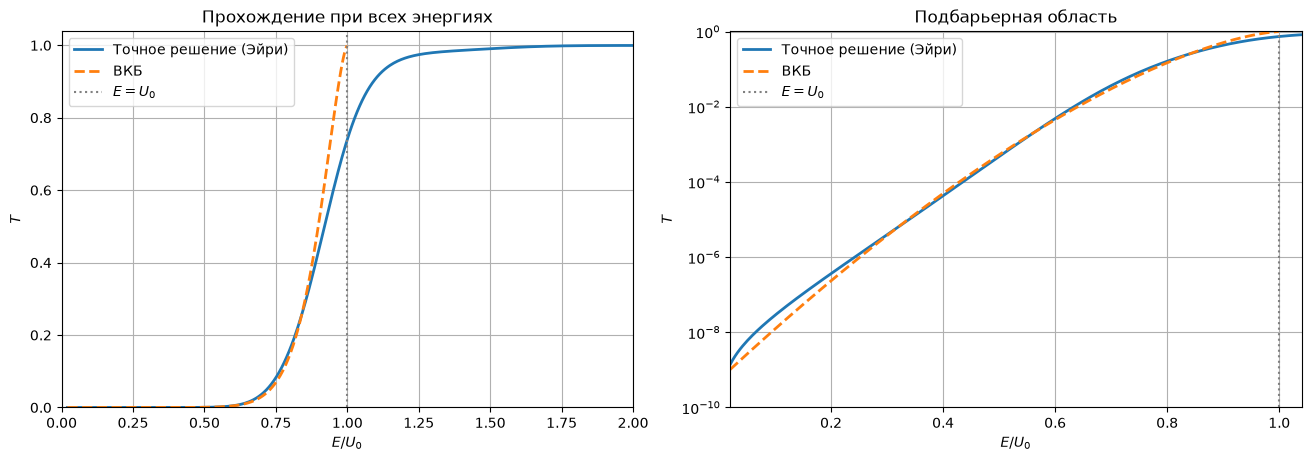

In [17]:
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(13, 4.5), layout="constrained"
)

for ax in (ax1, ax2):
    ax.plot(eps_grid, T_exact, lw=2, label="Точное решение (Эйри)")
    ax.plot(eps_grid, T_wkb, "--", lw=2, label="ВКБ")
    ax.axvline(1, color="gray", linestyle=":", label=r"$E=U_0$")
    ax.set_xlabel(r"$E/U_0$")
    ax.set_ylabel(r"$T$")
    ax.grid(True)
    ax.legend()

ax1.set_xlim(0, 2)
ax1.set_ylim(0, 1.04)
ax1.set_title("Прохождение при всех энергиях")

ax2.set_xlim(0.02, 1.04)
ax2.set_yscale("log")
ax2.set_ylim(1e-10, 1.05)
ax2.set_title("Подбарьерная область")

plt.show()